# INFO 450 Project: Flight Delays and Cancellations
## Team Members: Andrea Atoa Ortiz, Nahom Ghiorghis, Nathnael Abraham, Danny Truong
## Region: Texas

## Executive Summary

This project examines flight delays and cancellations at four Texas airports: DFW, IAH, AUS, and SAT. We use a sample of 60,000 scheduled departures from August 2025 through July 2026 from the Bureau of Transportation Statistics. Our research focuses on airport reliability, delay concentration by route, when delays occur, and differences between airlines.

Three findings stand out. First, SAT had the highest on-time arrival rate at 81.51%, while DFW had the lowest at 72.24%. Second, DFW had the highest cancellation rate at 2.90%, compared with IAH at 1.15%. Third, delays were concentrated across routes: 158 routes accounted for 80% of total positive arrival-delay minutes. The average arrival delay was 11.52 minutes, while the median was -5 minutes, showing that some longer delays raised the average.

We recommend that travelers compare both on-time and cancellation rates when choosing an airport. Airport managers may also want to examine DFW's reliability and delay patterns more closely. One limitation is that the dataset is a sample of approximately 60,000 departures rather than every flight during the year, so the results may not represent every flight or operating condition.

## Phase 1: Business Understanding

### Research Questions
1. How reliable are Texas airports? Compare DFW, IAH, AUS, and SAT based on on-time arrival percentages and cancellation rates.
2. How concentrated are flight delays? Do a small number of routes account for most delay minutes?
3. When are flight delays worst? Examine delays by month, day of the week, and departure time.
4. Which airlines are the most and least reliable in Texas?

### Target Audience
1. Travelers choosing between airports.
2. Airport authorities looking to improve flight reliability.
3. Corporate travel managers planning employee travel.

### Initial Expectations
1. Larger airports may experience more total delays due to higher flight volumes.
2. Flight delays may increase during certain months and times of the day.
3. A small number of routes may account for a large portion of total delay minutes.

## Phase 2: Data Understanding

The data comes from the Bureau of Transportation Statistics Reporting Carrier On-Time Performance database. Each row represents one scheduled departure. The Texas file contains flights from DFW, IAH, AUS, and SAT between August 2025 and July 2026.

We review the original data, including its row count, columns, data types, value ranges, duplicates, and missing values. We also use the carrier and airport lookup files to add descriptive information.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Load the original data and lookup files
data_folder = Path('data')
raw = pd.read_csv(data_folder / 'flights_Texas.csv')
carriers = pd.read_csv(data_folder / 'carriers.csv')
airports = pd.read_csv(data_folder / 'airports.csv')

print('Original data shape:', raw.shape)
print('Carrier lookup shape:', carriers.shape)
print('Airport lookup shape:', airports.shape)
raw.info()
display(raw.describe(include='all').T)

# Check exact duplicate rows
duplicate_count = raw.duplicated().sum()
print('Exact duplicate rows:', duplicate_count)

# Remove exact duplicates for the remaining checks
data = raw.drop_duplicates().copy()
print('Shape after removing duplicates:', data.shape)

# Check missing values and percentages
missing = pd.DataFrame({
    'Missing Count': data.isna().sum(),
    'Missing %': (data.isna().sum() / len(data) * 100).round(2)
})
display(missing[missing['Missing Count'] > 0].sort_values('Missing Count', ascending=False))

Original data shape: (60000, 37)
Carrier lookup shape: (13, 3)
Airport lookup shape: (359, 3)
<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 37 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             60000 non-null  int64  
 1   Quarter                          60000 non-null  int64  
 2   Month                            60000 non-null  int64  
 3   DayofMonth                       60000 non-null  int64  
 4   DayOfWeek                        60000 non-null  int64  
 5   FlightDate                       60000 non-null  str    
 6   Reporting_Airline                60000 non-null  str    
 7   DOT_ID_Reporting_Airline         60000 non-null  int64  
 8   Tail_Number                      59853 non-null  str    
 9   Flight_Number_Reporting_Airline  60000 non-null  int64  
 10  OriginAirportID                  60000 non-null  int64  
 1

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Year,60000.0,NaN,NaN,NaN,2025.58245,0.493159,2025.0,2025.0,2026.0,2026.0,2026.0
Quarter,60000.0,NaN,NaN,NaN,2.523133,1.106896,1.0,2.0,3.0,4.0,4.0
Month,60000.0,NaN,NaN,NaN,6.577533,3.393275,1.0,4.0,7.0,10.0,12.0
DayofMonth,60000.0,NaN,NaN,NaN,15.7699,8.785191,1.0,8.0,16.0,23.0,31.0
DayOfWeek,60000.0,NaN,NaN,NaN,3.9982,2.004661,1.0,2.0,4.0,6.0,7.0
FlightDate,60000,365,2026-06-15,214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reporting_Airline,60000,13,AA,20590,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DOT_ID_Reporting_Airline,60000.0,NaN,NaN,NaN,19967.74415,307.827371,19393.0,19805.0,19805.0,20304.0,20452.0
Tail_Number,59853,4769,N79402,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight_Number_Reporting_Airline,60000.0,NaN,NaN,NaN,2500.035667,1537.303487,5.0,1356.0,2251.0,3475.0,6539.0


Exact duplicate rows: 180
Shape after removing duplicates: (59820, 37)


,Missing Count,Missing %
CancellationCode,58538,97.86
WeatherDelay,45126,75.44
LateAircraftDelay,45126,75.44
NASDelay,45126,75.44
CarrierDelay,45126,75.44
SecurityDelay,45126,75.44
ArrDelay,1446,2.42
ArrDel15,1446,2.42
ActualElapsedTime,1446,2.42
ArrTime,1297,2.17


### Missing-Data Classification

Missing values are classified based on what each field represents and how missingness relates to other observed fields.

- **Structural:** The value does not apply to that flight, such as an arrival delay for a cancelled flight.
- **MAR:** Missingness may be related to another observed variable, such as cancellation status.
- **MCAR:** Missingness does not appear to be explained by observed variables. This cannot be proven from these checks, so any MCAR classification is tentative.
- **MNAR:** Missingness depends on the missing value itself. We do not have enough evidence to confidently classify a field as MNAR.

The cross-tabulations below help us examine patterns in missing values. They provide evidence for our decisions but do not prove the exact missingness mechanism.

In [2]:
# Compare missing values with other flight information
print('Missing departure time compared with cancellations:')
display(pd.crosstab(data['DepTime'].isna(), data['Cancelled'], margins=True))

print('Missing arrival delay compared with cancellations and diversions:')
display(pd.crosstab(data['ArrDelay'].isna(), [data['Cancelled'], data['Diverted']], margins=True))

print('Missing cancellation code compared with cancellation status:')
display(pd.crosstab(data['CancellationCode'].isna(), data['Cancelled'], margins=True))

print('Missing delay causes compared with the 15-minute arrival delay indicator:')
display(pd.crosstab(data['CarrierDelay'].isna(), data['ArrDel15'], margins=True))

print('Missing distance by origin airport:')
display(pd.crosstab(data['Distance'].isna(), data['Origin'], margins=True))

print('Missing distance by airline:')
display(pd.crosstab(data['Distance'].isna(), data['Reporting_Airline'], margins=True))

# Review missingness for each delay-cause field
cause_columns = ['CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay']
cause_missing = pd.DataFrame({
    'Missing Count': data[cause_columns].isna().sum(),
    'Missing %': (data[cause_columns].isna().mean() * 100).round(2)
})
display(cause_missing)

# Classification and evidence for columns with missing values
classifications = {
    'Tail_Number': ('MAR (tentative)', 'Aircraft identifiers may be missing for certain operational situations. More evidence would be needed to establish the exact cause.'),
    'DepTime': ('MAR (tentative)', 'Actual departure time may be unavailable when a flight is cancelled or does not depart normally.'),
    'DepDelay': ('MAR (tentative)', 'Departure delay depends on an actual departure and may be missing when a flight does not depart.'),
    'DepDel15': ('MAR (tentative)', 'The departure delay indicator depends on actual departure information.'),
    'TaxiOut': ('Structural / MAR', 'Taxi-out time may not exist when a flight does not depart.'),
    'ArrTime': ('Structural', 'A normal arrival time at the destination is unavailable for cancelled or diverted flights.'),
    'ArrDelay': ('Structural', 'Arrival delay at the destination is not defined for cancelled or diverted flights.'),
    'ArrDel15': ('Structural', 'The on-time arrival indicator is not defined for flights without a completed arrival.'),
    'ActualElapsedTime': ('Structural', 'Actual elapsed time is unavailable when a flight does not complete its scheduled trip.'),
    'CancellationCode': ('Structural', 'A cancellation reason only applies to a cancelled flight.'),
    'Distance': ('Uncertain / possible MCAR', 'We compared missing distance values by origin and airline. These checks can reveal patterns but cannot prove that missingness is random.'),
    'CarrierDelay': ('Structural / reporting-related', 'Delay-cause information is associated with qualifying delayed flights and may not be reported for flights without a qualifying delay.'),
    'WeatherDelay': ('Structural / reporting-related', 'Weather delay information may not be reported when a flight does not have a qualifying arrival delay.'),
    'NASDelay': ('Structural / reporting-related', 'NAS delay information may not be reported when a flight does not have a qualifying arrival delay.'),
    'SecurityDelay': ('Structural / reporting-related', 'Security delay information may not be reported when a flight does not have a qualifying arrival delay.'),
    'LateAircraftDelay': ('Structural / reporting-related', 'Late aircraft delay information may not be reported when a flight does not have a qualifying arrival delay.')
}

classification_rows = []
for column in data.columns:
    if data[column].isna().any():
        category, evidence = classifications.get(
            column,
            ('Review needed', 'The missingness pattern should be reviewed before deciding how to handle this field.')
        )
        classification_rows.append({
            'Column': column,
            'Missing Count': int(data[column].isna().sum()),
            'Missing %': round(data[column].isna().mean() * 100, 2),
            'Classification': category,
            'Evidence': evidence
        })

missing_classification = pd.DataFrame(classification_rows)
display(missing_classification)

Missing departure time compared with cancellations:


Cancelled,0.0,1.0,All
DepTime,,,
False,58538,47,58585
True,0,1235,1235
All,58538,1282,59820


Missing arrival delay compared with cancellations and diversions:


Cancelled    0.0        1.0    All
Diverted     0.0  1.0   0.0       
ArrDelay                          
False      58374    0     0  58374
True           0  164  1282   1446
All        58374  164  1282  59820

Missing cancellation code compared with cancellation status:


Cancelled,0.0,1.0,All
CancellationCode,,,
False,0,1282,1282
True,58538,0,58538
All,58538,1282,59820


... (4 outputs left out)

Missing distance by airline:


Reporting_Airline,AA,AS,B6,DL,F9,G4,MQ,NK,OH,OO,UA,WN,YX,All
Distance,,,,,,,,,,,,,,
False,20327,641,200,4109,1866,58,7091,1111,2443,4899,10545,5783,147,59220
True,211,6,2,50,18,0,53,11,19,45,117,67,1,600
All,20538,647,202,4159,1884,58,7144,1122,2462,4944,10662,5850,148,59820


,Missing Count,Missing %
CarrierDelay,45126,75.44
WeatherDelay,45126,75.44
NASDelay,45126,75.44
SecurityDelay,45126,75.44
LateAircraftDelay,45126,75.44


,Column,Missing Count,Missing %,Classification,Evidence
0,Tail_Number,147,0.25,MAR (tentative),Aircraft identifiers may be missing for certai...
1,DepTime,1235,2.06,MAR (tentative),Actual departure time may be unavailable when ...
2,DepDelay,1238,2.07,MAR (tentative),Departure delay depends on an actual departure...
3,DepDel15,1238,2.07,MAR (tentative),The departure delay indicator depends on actua...
4,TaxiOut,1278,2.14,Structural / MAR,Taxi-out time may not exist when a flight does...
5,ArrTime,1297,2.17,Structural,A normal arrival time at the destination is un...
6,ArrDelay,1446,2.42,Structural,Arrival delay at the destination is not define...
7,ArrDel15,1446,2.42,Structural,The on-time arrival indicator is not defined f...
8,CancellationCode,58538,97.86,Structural,A cancellation reason only applies to a cancel...
9,ActualElapsedTime,1446,2.42,Structural,Actual elapsed time is unavailable when a flig...


### Data-Quality Issue and Missing-Value Decisions

One issue that stood out was the large amount of missing information in the five delay-cause columns. These fields are not expected to be filled in for every flight. They describe reasons for qualifying arrival delays, so missing values should not automatically be treated as errors or replaced with zero. We check their relationship with ArrDel15 before using them.

Our handling decisions are:

- **Tail_Number:** Leave missing values blank because we do not have enough information to identify the aircraft.
- **DepTime, DepDelay, DepDel15, and TaxiOut:** Keep missing values when actual departure information is unavailable. Do not replace them with averages.
- **ArrTime, ArrDelay, ArrDel15, and ActualElapsedTime:** Keep these blank for cancelled and diverted flights. These flights remain in the cleaned dataset but are excluded from analyses requiring completed arrivals.
- **CancellationCode:** Keep blank for flights that were not cancelled because a cancellation reason does not apply to them.
- **Distance:** Do not guess or automatically impute missing distances. Exclude rows with missing distance only from analyses that specifically require it.
- **Delay-cause columns:** Keep missing values. Use these fields only when analyzing flights with ArrDel15 equal to 1, and do not assume that every missing cause means zero minutes.

Cancelled and diverted flights remain in the cleaned file because they are still scheduled flights. Cancellation and diversion rates use all scheduled flights, while arrival-delay statistics use completed flights only.

### Redundant Columns

We remove columns that repeat information available in other fields or can be calculated from fields we keep. We retain Month, DayOfWeek, ArrDel15, and DistanceGroup because they are useful for later analysis.

| Column removed | Reason |
|---|---|
| Year | Can be obtained from FlightDate. |
| Quarter | Can be determined from the month. |
| DayofMonth | The full FlightDate already contains this information. |
| DOT_ID_Reporting_Airline | The airline code is already available in Reporting_Airline. |
| OriginAirportID | The origin airport code is already available in Origin. |
| OriginStateFips | State information can be obtained from the airport lookup. |
| DepTimeBlk | Departure time periods can be determined from CRSDepTime. |
| Flights | Each row represents one scheduled flight, so this field does not add information. |

## Phase 3: Data Preparation

We remove exact duplicates, drop redundant columns, merge the carrier and destination airport lookup files, and create derived columns. We keep missing values when they are structural or cannot be reliably filled. The cleaned file retains all scheduled flights, including cancelled and diverted flights.

In [3]:
# Start with the data after exact duplicates were removed
df = data.copy()
rows_before_cleaning = len(raw)
rows_after_duplicates = len(df)

# Remove redundant columns
remove_columns = [
    'Year', 'Quarter', 'DayofMonth', 'DOT_ID_Reporting_Airline',
    'OriginAirportID', 'OriginStateFips', 'DepTimeBlk', 'Flights'
]
df = df.drop(columns=remove_columns, errors='ignore')

# Check lookup file columns before merging
required_carrier_columns = {'Code', 'Carrier', 'CarrierType'}
required_airport_columns = {'Code', 'City', 'State'}

missing_carrier_columns = required_carrier_columns - set(carriers.columns)
missing_airport_columns = required_airport_columns - set(airports.columns)

assert not missing_carrier_columns, f'Missing carrier lookup columns: {missing_carrier_columns}'
assert not missing_airport_columns, f'Missing airport lookup columns: {missing_airport_columns}'

# The carrier lookup uses the column Carrier, which we rename to AirlineName
carrier_lookup = carriers[['Code', 'Carrier', 'CarrierType']].drop_duplicates(subset=['Code'])
df = df.merge(
    carrier_lookup,
    left_on='Reporting_Airline',
    right_on='Code',
    how='left',
    validate='many_to_one'
)
df = df.rename(columns={'Carrier': 'AirlineName'})
df = df.drop(columns=['Code'])

# Merge destination airport information using the destination airport code
airport_lookup = airports[['Code', 'City', 'State']].drop_duplicates(subset=['Code'])
df = df.merge(
    airport_lookup,
    left_on='Dest',
    right_on='Code',
    how='left',
    validate='many_to_one'
)
df = df.rename(columns={'City': 'DestinationCity', 'State': 'DestinationState'})
df = df.drop(columns=['Code'])

# Verify that the merges worked
print('Missing airline names:', df['AirlineName'].isna().sum())
print('Missing carrier types:', df['CarrierType'].isna().sum())
print('Missing destination cities:', df['DestinationCity'].isna().sum())
print('Missing destination states:', df['DestinationState'].isna().sum())

print('Rows before cleaning:', rows_before_cleaning)
print('Rows after removing duplicates:', rows_after_duplicates)
print('Rows after both merges:', len(df))

assert len(df) == rows_after_duplicates, 'A lookup merge changed the number of flight rows.'
assert df['AirlineName'].notna().all(), 'Some airline names did not match the carrier lookup.'
assert df['CarrierType'].notna().all(), 'Some carrier types did not match the carrier lookup.'
assert df['DestinationCity'].notna().all(), 'Some destinations did not match the airport lookup.'
assert df['DestinationState'].notna().all(), 'Some destination states did not match the airport lookup.'

# Create derived columns
df['FlightDate'] = pd.to_datetime(df['FlightDate'])
df['CRSDepTime'] = pd.to_numeric(df['CRSDepTime'], errors='coerce')
df['DepHour'] = (df['CRSDepTime'] // 100).astype('Int64')
df['Weekend'] = df['DayOfWeek'].isin([6, 7]).astype(int)
df['Route'] = df['Origin'].astype(str) + '-' + df['Dest'].astype(str)

df['DelayCategory'] = pd.cut(
    df['ArrDelay'],
    bins=[float('-inf'), 0, 15, 60, float('inf')],
    labels=['Early', 'On Schedule', 'Minor Delay', 'Major Delay'],
    right=False
)

# Negative arrival delays are retained for regular delay statistics.
# DelayMinutes is clipped at zero only for delay-concentration analysis.
df['DelayMinutes'] = df['ArrDelay'].clip(lower=0)

# Verify derived columns
print('Departure hour range:', df['DepHour'].min(), 'to', df['DepHour'].max())
print('Weekend values:', sorted(df['Weekend'].dropna().unique()))
print('Missing route values:', df['Route'].isna().sum())
print('Missing delay categories:', df['DelayCategory'].isna().sum())

assert df['DepHour'].dropna().between(0, 23).all()
assert df['Weekend'].isin([0, 1]).all()
assert (df['Route'] == df['Origin'].astype(str) + '-' + df['Dest'].astype(str)).all()
assert (df['DelayMinutes'].fillna(-999) == df['ArrDelay'].clip(lower=0).fillna(-999)).all()

# Save the cleaned data
df.to_csv(data_folder / 'flights_clean.csv', index=False)

print('Final cleaned data shape:', df.shape)
print('Cleaned data saved to data/flights_clean.csv')
display(df.head())

Missing airline names: 0
Missing carrier types: 0
Missing destination cities: 0
Missing destination states: 0
Rows before cleaning: 60000
Rows after removing duplicates: 59820
Rows after both merges: 59820
Departure hour range: 5 to 23
Weekend values: [np.int64(0), np.int64(1)]
Missing route values: 0
Missing delay categories: 1446
Final cleaned data shape: (59820, 38)
Cleaned data saved to data/flights_clean.csv


,Month,DayOfWeek,FlightDate,Reporting_Airline,Tail_Number,Flight_Number_Reporting_Airline,Origin,Dest,CRSDepTime,DepTime,...,LateAircraftDelay,AirlineName,CarrierType,DestinationCity,DestinationState,DepHour,Weekend,Route,DelayCategory,DelayMinutes
0,8,5,2025-08-01,AA,N535UW,575,DFW,CLT,500,501.0,...,NaN,American Airlines,Mainline,Charlotte,NC,5,0,DFW-CLT,Early,0.0
1,8,5,2025-08-01,AA,N907NN,1360,DFW,ORD,500,459.0,...,NaN,American Airlines,Mainline,Chicago,IL,5,0,DFW-ORD,Early,0.0
2,8,5,2025-08-01,AA,N947NN,1618,DFW,DCA,507,NaN,...,NaN,American Airlines,Mainline,Washington,VA,5,0,DFW-DCA,NaN,NaN
3,8,5,2025-08-01,DL,N359DN,1344,AUS,ATL,535,607.0,...,NaN,Delta Air Lines,Mainline,Atlanta,GA,5,0,AUS-ATL,On Schedule,14.0
4,8,5,2025-08-01,WN,N8852Q,2713,AUS,HOU,555,553.0,...,NaN,Southwest Airlines,Mainline,Houston,TX,5,0,AUS-HOU,Early,0.0


### Cleaning Results

The original file contained 60,000 rows. We found 180 exact duplicate rows and removed the extra copies, leaving 59,820 scheduled flights. The carrier lookup was joined using Reporting_Airline and the Code field in carriers.csv. The destination airport lookup was joined using Dest and Code in airports.csv. We checked that both merges preserved the row count and that the lookup fields were populated.

We created DepHour from scheduled departure time, Weekend from DayOfWeek, Route from Origin and Dest, DelayCategory from ArrDelay, and DelayMinutes by setting negative arrival delays to zero. The cleaned file keeps cancelled and diverted flights. We exclude them only from analyses where a completed arrival is required.

## Phase 4: Analysis - Early Findings

A completed flight is one where Cancelled equals 0 and Diverted equals 0. On-time arrival percentage is calculated using completed flights only. Cancellation and diversion rates use all scheduled flights. Negative arrival delays are kept for normal arrival-delay statistics. Positive delay minutes are used only for delay-concentration analysis.

Scheduled flights: 59820
Completed flights: 58374
Cancelled flights: 1282
Diverted flights: 164


,Scheduled,Cancelled,Diverted,Cancellation %,Diversion %,On-Time %,Mean Arrival Delay
Origin,,,,,,,
AUS,9539,112.0,23.0,1.17,0.24,76.35,9.31
DFW,33341,966.0,95.0,2.90,0.28,72.24,13.96
IAH,12625,145.0,35.0,1.15,0.28,78.10,8.93
SAT,4315,59.0,11.0,1.37,0.25,81.51,5.40


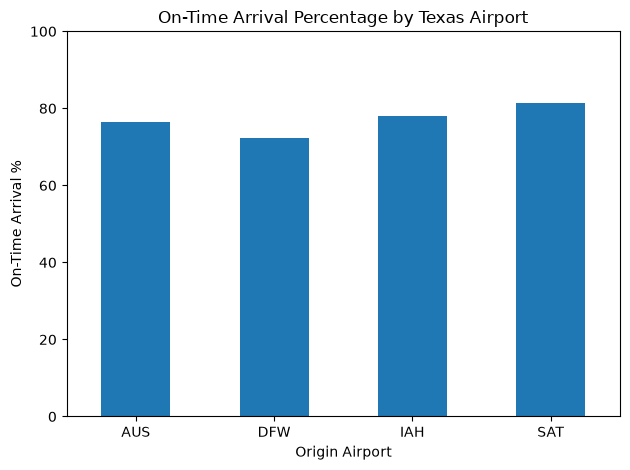

SAT has the highest on-time percentage at 81.51%.
DFW has the lowest on-time percentage at 72.24%.
DFW has the highest cancellation rate at 2.90%.
IAH has the lowest cancellation rate at 1.15%.


In [4]:
# Load the cleaned data
df = pd.read_csv(data_folder / 'flights_clean.csv', parse_dates=['FlightDate'])

# Completed flights only for arrival analysis
comp = df[(df['Cancelled'] == 0) & (df['Diverted'] == 0)].copy()

print('Scheduled flights:', len(df))
print('Completed flights:', len(comp))
print('Cancelled flights:', int(df['Cancelled'].sum()))
print('Diverted flights:', int(df['Diverted'].sum()))

# Research Question 1: Airport reliability
airport_table = df.groupby('Origin').agg(
    Scheduled=('Origin', 'size'),
    Cancelled=('Cancelled', 'sum'),
    Diverted=('Diverted', 'sum')
)

airport_table['Cancellation %'] = (airport_table['Cancelled'] / airport_table['Scheduled'] * 100).round(2)
airport_table['Diversion %'] = (airport_table['Diverted'] / airport_table['Scheduled'] * 100).round(2)
airport_table['On-Time %'] = comp.groupby('Origin')['ArrDel15'].apply(lambda x: (x == 0).mean() * 100).round(2)
airport_table['Mean Arrival Delay'] = comp.groupby('Origin')['ArrDelay'].mean().round(2)

display(airport_table)

airport_table['On-Time %'].plot(
    kind='bar', title='On-Time Arrival Percentage by Texas Airport',
    ylabel='On-Time Arrival %', xlabel='Origin Airport', rot=0
)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

best_airport = airport_table['On-Time %'].idxmax()
lowest_airport = airport_table['On-Time %'].idxmin()
highest_cancel = airport_table['Cancellation %'].idxmax()
lowest_cancel = airport_table['Cancellation %'].idxmin()

print(f'{best_airport} has the highest on-time percentage at {airport_table.loc[best_airport, "On-Time %"]:.2f}%.')
print(f'{lowest_airport} has the lowest on-time percentage at {airport_table.loc[lowest_airport, "On-Time %"]:.2f}%.')
print(f'{highest_cancel} has the highest cancellation rate at {airport_table.loc[highest_cancel, "Cancellation %"]:.2f}%.')
print(f'{lowest_cancel} has the lowest cancellation rate at {airport_table.loc[lowest_cancel, "Cancellation %"]:.2f}%.')

### Airport Reliability Interpretation

SAT had the highest on-time arrival percentage in this sample, while DFW had the lowest. DFW also had the highest cancellation rate. This shows why airport reliability should be evaluated using both on-time arrivals and cancellations. The on-time percentage uses completed flights only, while cancellation and diversion rates use all scheduled flights.

,Total Positive Delay Minutes
Route,
IAH-ORD,18173.0
DFW-ORD,18115.0
DFW-LGA,15459.0
IAH-DFW,15007.0
DFW-DEN,14380.0
DFW-IAH,13892.0
DFW-MCO,13482.0
DFW-ATL,12925.0
DFW-SAT,12342.0


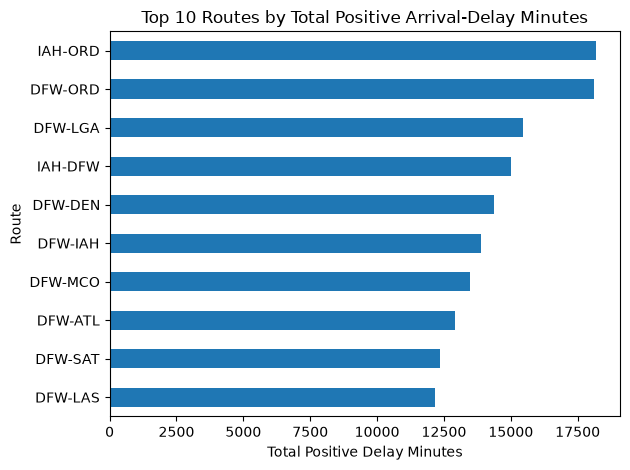

The route with the most positive delay minutes is IAH-ORD, with 18,173 minutes.
158 routes account for at least 80% of total positive delay minutes.
Flight-level Gini coefficient: 0.8484


In [5]:
# Research Question 2: Positive arrival-delay minutes by route
comp['DelayMinutes'] = comp['ArrDelay'].clip(lower=0)
route_delays = comp.groupby('Route')['DelayMinutes'].sum().sort_values(ascending=False)
top_routes = route_delays.head(10)

display(top_routes.to_frame(name='Total Positive Delay Minutes'))

top_routes.sort_values().plot(
    kind='barh', title='Top 10 Routes by Total Positive Arrival-Delay Minutes',
    xlabel='Total Positive Delay Minutes', ylabel='Route'
)
plt.tight_layout()
plt.show()

if len(top_routes) > 0:
    print(f'The route with the most positive delay minutes is {top_routes.index[0]}, with {top_routes.iloc[0]:,.0f} minutes.')

# Early concentration calculation across all routes
total_delay_minutes = route_delays.sum()
route_cumulative = route_delays.cumsum() / total_delay_minutes * 100
routes_for_80 = int((route_cumulative < 80).sum() + 1)
print(f'{routes_for_80} routes account for at least 80% of total positive delay minutes.')

# Flight-level Gini coefficient for positive delay minutes
def gini(values):
    values = pd.Series(values).dropna().clip(lower=0).sort_values().to_numpy()
    if len(values) == 0 or values.sum() == 0:
        return 0.0
    n = len(values)
    index = range(1, n + 1)
    return (2 * sum(i * value for i, value in zip(index, values)) / (n * values.sum())) - ((n + 1) / n)

flight_gini = gini(comp['DelayMinutes'])
print(f'Flight-level Gini coefficient: {flight_gini:.4f}')

### Route Delay Interpretation

The route chart ranks the ten routes with the highest total positive arrival-delay minutes. The concentration calculation uses all routes, not just the ten displayed. A smaller number of routes accounting for a large share of delay minutes indicates that delays are not evenly distributed across routes. The Gini coefficient provides another measure of how unevenly positive delay minutes are distributed across individual flights. These measures describe concentration, not the cause of delays.

,On-Time Arrival %
FlightDate,
2025-08,69.77
2025-09,80.75
2025-10,77.31
2025-11,76.79
2025-12,75.48
2026-01,79.48
2026-02,81.61
2026-03,74.20
2026-04,76.32


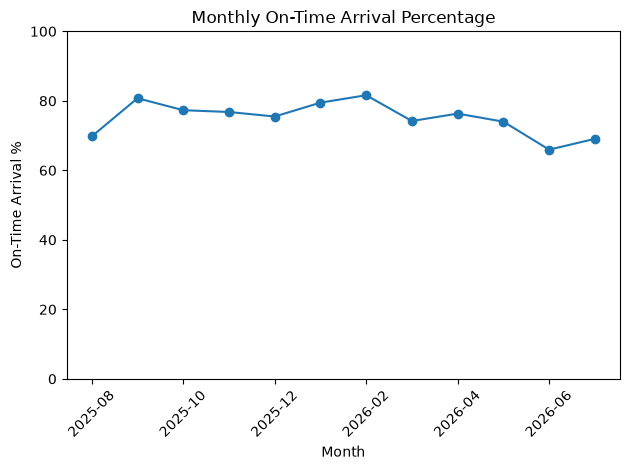

,Average Arrival Delay
DepHour,
5,-5.09
6,0.54
7,0.30
8,2.24
9,3.74
10,5.45
11,9.02
12,8.83
13,13.75


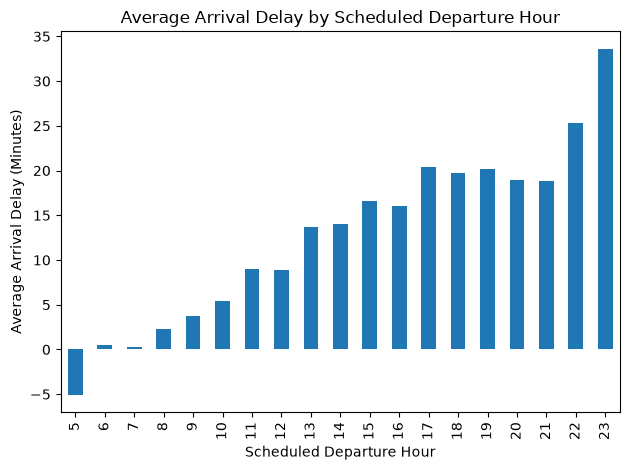

,On-Time Arrival %
DayOfWeek,
1,73.08
2,79.42
3,78.28
4,75.22
5,74.41
6,73.63
7,70.01


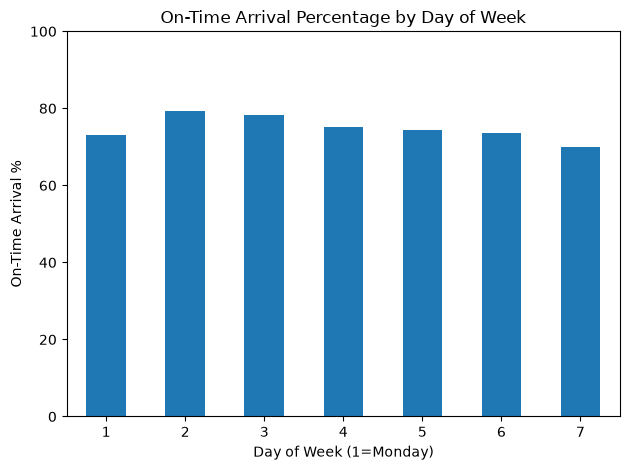

In [6]:
# Research Question 3: Timing of delays
monthly_ontime = comp.groupby(comp['FlightDate'].dt.to_period('M'))['ArrDel15'].apply(lambda x: (x == 0).mean() * 100)
monthly_ontime.index = monthly_ontime.index.astype(str)
display(monthly_ontime.to_frame(name='On-Time Arrival %').round(2))

monthly_ontime.plot(
    kind='line', marker='o', title='Monthly On-Time Arrival Percentage',
    xlabel='Month', ylabel='On-Time Arrival %'
)
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Average arrival delay by scheduled departure hour
hourly_delay = comp.groupby('DepHour')['ArrDelay'].mean()
display(hourly_delay.round(2).to_frame(name='Average Arrival Delay'))

hourly_delay.plot(
    kind='bar', title='Average Arrival Delay by Scheduled Departure Hour',
    xlabel='Scheduled Departure Hour', ylabel='Average Arrival Delay (Minutes)'
)
plt.tight_layout()
plt.show()

# On-time percentage by day of week
weekday_ontime = comp.groupby('DayOfWeek')['ArrDel15'].apply(lambda x: (x == 0).mean() * 100)
display(weekday_ontime.round(2).to_frame(name='On-Time Arrival %'))

weekday_ontime.plot(
    kind='bar', title='On-Time Arrival Percentage by Day of Week',
    xlabel='Day of Week (1=Monday)', ylabel='On-Time Arrival %', rot=0
)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Timing Interpretation

The monthly chart shows how on-time arrival percentages change throughout the August 2025 to July 2026 period. The hourly chart compares average arrival delays by scheduled departure hour, and the weekday chart compares on-time percentages by day of the week. These patterns help identify when travelers may experience more delays. Smaller groups and individual months may be more variable because the dataset is a sample.

In [7]:
# Research Question 4: Airline reliability
airline_table = comp.groupby(['AirlineName', 'CarrierType']).agg(
    Completed_Flights=('ArrDel15', 'size'),
    On_Time_Percentage=('ArrDel15', lambda x: (x == 0).mean() * 100),
    Average_Arrival_Delay=('ArrDelay', 'mean')
)

airline_table['On_Time_Percentage'] = airline_table['On_Time_Percentage'].round(2)
airline_table['Average_Arrival_Delay'] = airline_table['Average_Arrival_Delay'].round(2)

# Rank airlines with at least 30 completed flights
ranked_airlines = airline_table[airline_table['Completed_Flights'] >= 30].sort_values(
    'On_Time_Percentage', ascending=False
)
display(ranked_airlines)

# Compare carrier types
carrier_type_table = comp.groupby('CarrierType').agg(
    Completed_Flights=('ArrDel15', 'size'),
    On_Time_Percentage=('ArrDel15', lambda x: (x == 0).mean() * 100),
    Average_Arrival_Delay=('ArrDelay', 'mean')
)

carrier_type_table['On_Time_Percentage'] = carrier_type_table['On_Time_Percentage'].round(2)
carrier_type_table['Average_Arrival_Delay'] = carrier_type_table['Average_Arrival_Delay'].round(2)
display(carrier_type_table)

,,Completed_Flights,On_Time_Percentage,Average_Arrival_Delay
AirlineName,CarrierType,,,
Envoy Air,Regional,6962,82.06,3.25
Delta Air Lines,Mainline,4068,81.81,5.60
United Airlines,Mainline,10533,79.91,5.56
Alaska Airlines,Mainline,639,77.62,4.81
SkyWest Airlines,Regional,4827,77.03,11.56
Republic Airways,Regional,143,76.92,8.51
PSA Airlines,Regional,2354,75.87,13.18
Southwest Airlines,Mainline,5799,75.20,7.39
Spirit Airlines,Low-cost,1086,72.84,11.57


,Completed_Flights,On_Time_Percentage,Average_Arrival_Delay
CarrierType,,,
Low-cost,2991,72.55,13.39
Mainline,41097,73.44,12.69
Regional,14286,79.29,7.75


### Airline Interpretation

The airline table compares completed flights using on-time arrival percentage and average arrival delay. Only airlines with at least 30 completed flights are included in the ranking to avoid drawing conclusions from very small groups. The carrier-type table compares the carrier categories available in the lookup file. These results help us evaluate whether reliability differs between individual airlines and airline groups.

## Early Insights and Next Steps

Our airport comparison shows that SAT had the highest on-time arrival percentage at 81.51%, while DFW had the lowest at 72.24%. DFW had the highest cancellation rate at 2.90%, while IAH had the lowest at 1.15%.

The route analysis shows that delay minutes are concentrated across routes, with 158 routes accounting for 80% of total positive arrival-delay minutes. The average arrival delay was 11.52 minutes, while the median was -5 minutes. This suggests that some longer delays raise the average even though the median flight arrived early.

The monthly, weekday, and hourly comparisons provide an initial look at when delays occur. The airline tables allow us to compare individual airlines and carrier types.

Next, we will complete the remaining descriptive and inferential statistics required for the final project, including confidence intervals, group comparisons, and correlation analysis. We will also finish the required visualizations, answer each research question, discuss limitations, and build the Streamlit app. We would like feedback on whether our missing-value decisions and early airport comparisons are clear and appropriate.

## AI Use Disclosure

AI tools were used to assist with organizing the notebook, reviewing Python code, and improving explanations of data preparation and analysis. The team is responsible for checking the code, verifying the results, and writing the final interpretation of the findings.